# Lab Assignment 12 — Tutorial Demo
## Mixture of Experts: many small networks, and a router that decides who works

The lecture (*Introduction to Mixture of Experts*, parts 1 and 2) builds up one idea: instead of one
big network that processes every input, keep **several smaller networks — the experts** — and a small
**gating network — the router** — that decides which expert handles each input.

$$y = G(x)_1\,E_1(x) + G(x)_2\,E_2(x) + \dots + G(x)_n\,E_n(x)$$

Today we build that on a toy problem small enough to see on one plot, and watch the router learn.

| Demo section | What we build |
|---|---|
| 1. A problem one network cannot solve | four clusters, each with its own rule |
| 2. A mixture of experts | four linear experts + a soft gate |
| 3. Top-1 routing | each point goes to **one** expert only |
| 4. Who goes where | the cluster × expert table from the slides |
| 5. When routing goes wrong | two clusters, one expert — and what your assignment does |

> **Your assignment is deliberately NOT this.** You will put an MoE layer **inside a Transformer** that
> classifies **news articles**, route **every token** separately, and measure the things the second
> lecture worries about: noisy top-k gating, load balancing, and dropped tokens.

In [1]:
import math
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

---
## 1. A problem one network cannot solve

This is the toy from the lecture's slide *"Why do experts not collapse in practice?"*: **four
clusters**, and inside each cluster the two classes are split by a straight line — but **each cluster
has its own line**, pointing a different way.

So each cluster on its own is easy (one straight line solves it), but no single straight line can
solve all four at once.

600 points, 4 clusters, classes: [297, 303]


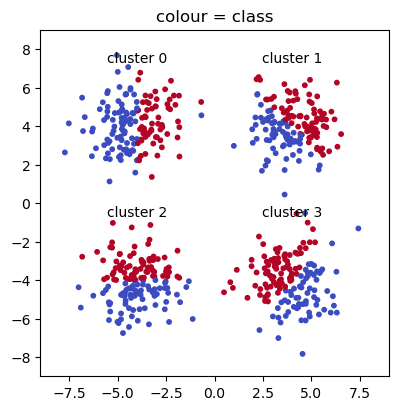

In [2]:
def make_clusters(n_per_cluster=150, seed=0):
    rng = np.random.default_rng(seed)
    centres = [(-4, 4), (4, 4), (-4, -4), (4, -4)]
    angles  = [0, 45, 90, 135]                       # each cluster's OWN dividing line (degrees)
    X, y, cluster = [], [], []
    for k, ((cx, cy), a) in enumerate(zip(centres, angles)):
        p = rng.normal(0, 1.2, size=(n_per_cluster, 2))
        normal = np.array([math.cos(math.radians(a)), math.sin(math.radians(a))])
        X.append(p + [cx, cy])
        y.append((p @ normal > 0).astype(int))       # which side of THIS cluster's line
        cluster.append(np.full(n_per_cluster, k))
    return (torch.tensor(np.vstack(X), dtype=torch.float32),
            torch.tensor(np.concatenate(y)), np.concatenate(cluster))

X, y, cluster = make_clusters()
print(f"{len(X)} points, {len(set(cluster))} clusters, classes: {y.bincount().tolist()}")

plt.figure(figsize=(4.5, 4.5))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', s=10)
for k, (cx, cy) in enumerate([(-4, 4), (4, 4), (-4, -4), (4, -4)]):
    plt.text(cx, cy + 3.3, f"cluster {k}", ha='center', fontsize=10)
plt.title("colour = class"); plt.xlim(-9, 9); plt.ylim(-9, 9); plt.show()

In [3]:
def train(model, epochs=600, lr=0.1):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    for _ in range(epochs):
        out = model(X)
        out = out[0] if isinstance(out, tuple) else out      # MoE models also return the gate
        loss = F.cross_entropy(out, y)
        opt.zero_grad(); loss.backward(); opt.step()
    return model

def accuracy(model):
    out = model(X)
    out = out[0] if isinstance(out, tuple) else out
    return (out.argmax(1) == y).float().mean().item()

torch.manual_seed(0)
one_model = train(nn.Linear(2, 2))                      # ONE linear classifier for everything
print(f"one linear model: accuracy {accuracy(one_model):.3f}   (guessing = 0.5)")

one linear model: accuracy 0.563   (guessing = 0.5)


One straight line gets barely better than a coin toss. It is not a training problem — the right
answer simply cannot be drawn with one line.

---
## 2. A mixture of experts

Now give the model **four** linear classifiers — the **experts** — and a **gate** that looks at the
input and outputs four weights that add up to 1:

$$G(x) = \text{softmax}(W_g\,x) \qquad\qquad y = \sum_{i=1}^{4} G(x)_i\,E_i(x)$$

Each expert is still just one straight line. The gate's job is to learn **which expert to trust
where**. Everything — experts and gate — is trained together by ordinary backpropagation.

In [4]:
class MixtureOfExperts(nn.Module):
    def __init__(self, n_experts=4, top1=False):
        super().__init__()
        self.experts = nn.ModuleList([nn.Linear(2, 2) for _ in range(n_experts)])  # 4 linear experts
        self.gate    = nn.Linear(2, n_experts)                                    # the router
        self.top1    = top1

    def forward(self, x):
        G = F.softmax(self.gate(x), dim=-1)                  # (n, 4): how much to trust each expert
        if self.top1:                                        # section 3: keep ONLY the winner
            G = G * F.one_hot(G.argmax(-1), G.shape[1])
        outputs = torch.stack([e(x) for e in self.experts], dim=1)    # (n, 4, 2)
        return (G.unsqueeze(-1) * outputs).sum(dim=1), G     # y = sum_i G_i * E_i(x)

torch.manual_seed(0)
soft = train(MixtureOfExperts())
print(f"soft mixture of 4 experts: accuracy {accuracy(soft):.3f}\n")

_, G = soft(X)
print("gate weights for the first point of each cluster:")
for k in range(4):
    i = int(np.where(cluster == k)[0][0])
    print(f"  cluster {k}:  {np.round(G[i].detach().numpy(), 2)}")

soft mixture of 4 experts: accuracy 0.915

gate weights for the first point of each cluster:
  cluster 0:  [0.24 0.   0.   0.76]
  cluster 1:  [0.12 0.84 0.   0.04]
  cluster 2:  [0.11 0.   0.88 0.01]
  cluster 3:  [0.23 0.72 0.05 0.01]


A big jump from one line. But look at the gate weights: for some clusters the gate **hedges** — it
blends two or three experts instead of committing to one. Blending lets the experts lean on each
other, so no expert is forced to own a cluster completely.

---
## 3. Top-1 routing

The lecture's *greedy expert selection* slide: pick **only the best** expert and use its weight.

$$i^* = \arg\max_i\, G(x)_i \qquad\qquad y = G(x)_{i^*}\,E_{i^*}(x)$$

One change in the code — the `top1=True` line. Two things follow:

- **Cheaper.** Each input needs only **one** expert. With 4 experts that is a quarter of the compute;
  with 128 experts it is 1/128. This is the whole reason big MoE models exist.
- **The router still learns.** The output is multiplied by $G(x)_{i^*}$, a softmax probability, so the
  gradient reaches the gate through that number — exactly the slide's
  $\nabla L / \nabla G(x)_{i^*} = E_{i^*}(x)^T\, \nabla L/\nabla y$.

(For clarity this demo still computes all four experts and then zeroes three. A real sparse layer
runs **only** the chosen expert on each input — you will write that in the assignment.)

In [5]:
torch.manual_seed(0)
top1 = train(MixtureOfExperts(top1=True))
print(f"top-1 routing:             accuracy {accuracy(top1):.3f}")
print(f"soft mixture (section 2):  accuracy {accuracy(soft):.3f}")

top-1 routing:             accuracy 0.988
soft mixture (section 2):  accuracy 0.915


Forcing a decision **helps**: each expert now has to own its points, so it specialises.

---
## 4. Who goes where

The lecture defines $n_{k,m}$ = the number of points from **cluster k** that are routed to **expert m**.
If the experts have specialised, each row has one big number. The slides also use the **routing
entropy** of each cluster: 0 means the whole cluster goes to one expert, $\log 4 = 1.39$ means it is
spread evenly over all four.

n[k, m] = points from cluster k sent to expert m

            expert 0   expert 1   expert 2   expert 3      entropy
cluster 0   0          0          0          150           0.00
cluster 1   149        0          1          0             0.04
cluster 2   0          150        0          0             0.00
cluster 3   0          0          150        0             0.00

share of points per expert: [0.25 0.25 0.25 0.25]


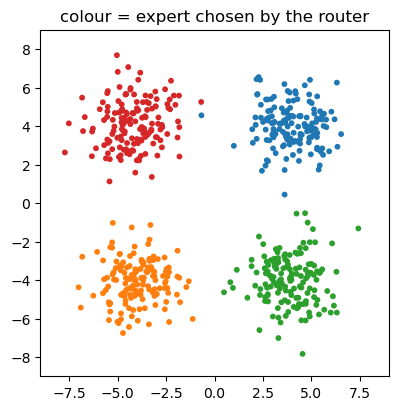

In [6]:
_, G = top1(X)
expert = G.argmax(1).numpy()

print("n[k, m] = points from cluster k sent to expert m\n")
print("            " + "".join(f"expert {m:<4}" for m in range(4)) + "   entropy")
for k in range(4):
    row = np.array([np.sum((cluster == k) & (expert == m)) for m in range(4)])
    p = row[row > 0] / row.sum()
    entropy = abs(-(p * np.log(p)).sum())
    print(f"cluster {k}   " + "".join(f"{n:<11}" for n in row) + f"   {entropy:.2f}")
print("\nshare of points per expert:", np.round(np.bincount(expert, minlength=4) / len(expert), 2))

plt.figure(figsize=(4.5, 4.5))
plt.scatter(X[:, 0], X[:, 1], c=expert, cmap='tab10', vmin=0, vmax=9, s=10)
plt.title("colour = expert chosen by the router"); plt.xlim(-9, 9); plt.ylim(-9, 9); plt.show()

Nobody told the router where the clusters are. It discovered them, because sending each cluster to
its own expert is what makes the loss go down. The lecture calls these two phases the **exploration
stage** (experts drift apart while the router is still near random) and the **router learning stage**
(the router learns to dispatch).

---
## 5. When routing goes wrong

Same data, same code, a different random starting point:

In [7]:
torch.manual_seed(4)
unlucky = train(MixtureOfExperts(top1=True))
_, G = unlucky(X)
expert = G.argmax(1).numpy()
print(f"top-1 routing, seed 4: accuracy {accuracy(unlucky):.3f}\n")
print("            " + "".join(f"expert {m:<4}" for m in range(4)))
for k in range(4):
    print(f"cluster {k}   " + "".join(f"{np.sum((cluster == k) & (expert == m)):<11}" for m in range(4)))
print("\nshare of points per expert:", np.round(np.bincount(expert, minlength=4) / len(expert), 2))

top-1 routing, seed 4: accuracy 0.868

            expert 0   expert 1   expert 2   expert 3   
cluster 0   0          0          3          147        
cluster 1   0          0          150        0          
cluster 2   0          69         81         0          
cluster 3   148        0          2          0          

share of points per expert: [0.25 0.12 0.39 0.24]


Look at the table: one expert is handed a whole cluster **plus** a large part of another — two
different rules, but it can only draw **one** straight line — while another expert gets only a small
share. Accuracy drops.

This is a small version of a failure the lecture lists under the **cons** of sparse MoE: **router
collapse** — the router sends too much to too few experts. Nothing in the loss above says "use your
experts evenly", so nothing stops it.

**The fix, in one sentence (you implement it in the assignment):** add a second, small loss term that
is smallest when every expert gets an equal share of the inputs — the Switch Transformer's
**load-balancing loss**.

---
## What your assignment does

| | This demo | Your assignment |
|---|---|---|
| Data | 2-D toy points | **news articles** (AG News: World, Sports, Business, Sci/Tech) |
| Where the MoE sits | the whole model | the **feed-forward layer of a Transformer block** |
| What is routed | one point at a time | **every token** separately |
| Experts | 4 straight lines | 8 small feed-forward networks |
| Router | softmax, top-1 | **noisy top-k** (Shazeer), then the **Switch** router |
| Computation | all experts run, 3 zeroed | only the chosen experts run (**sparse**) |
| What you measure | accuracy, who-goes-where | router learning, **load balance**, **dropped tokens**, what experts specialise in |

**Task 1** builds the MoE layer. **Task 2** trains it and finds a trap that the lecture hints at.
**Task 3** adds the load-balancing loss from section 5. **Task 4** gives every expert a fixed
**capacity** and counts the tokens that do not fit. **Task 5** asks the question from the Mixtral
slides: *do experts specialise by topic?*